In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/Student_Depression_Dataset.csv')

In [3]:
print(df.head())

   Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle Health_condition  \
0     Bachelor                 8  3.43           Yes         Critical   
1     Bachelor                 2  3.70           Yes         Abnormal   
2       Family                 8  3.28            No         Abnormal   
3       Family                 2  3.77            No             Good   
4       Family                 1  4.00            No         Abnormal   

   Cost_without_study Home_division Depression  
0               10113    Chittagong        Yes  
1               13815    Chittagong 

In [4]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB
None


In [5]:
print(df.isnull().sum())

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64


In [ ]:
print("Data duplikat:", df.duplicated().sum())


Data duplikat: 0


In [ ]:
print(df.describe())

             usia  lama_berlangganan_bulan  frekuensi_kunjungan_bulan  \
count  600.000000               600.000000                 600.000000   
mean    38.751667                29.718333                   4.405000   
std     12.473277                17.731130                   2.676986   
min     18.000000                 1.000000                   0.000000   
25%     28.000000                14.000000                   2.000000   
50%     39.000000                29.000000                   4.000000   
75%     49.000000                45.000000                   6.000000   
max     60.000000                60.000000                  14.000000   

       jumlah_transaksi  rata_rata_rating  total_belanja       churn  
count        600.000000        600.000000   6.000000e+02  600.000000  
mean          11.593333          3.622833   2.908211e+06    0.303333  
std            5.853637          0.729279   2.286523e+06    0.460082  
min            0.000000          1.200000   0.000000e+00  

In [6]:
# Pengecekan data duplikat spesifik dataset Student Depression
jumlah_duplikat = df.duplicated().sum()
total_data = len(df)

print(f"Data duplikat: {jumlah_duplikat} dari {total_data} responden ({(jumlah_duplikat/total_data)*100:.2f}%)")

Data duplikat: 0 dari 4464 responden (0.00%)


In [7]:
# Menghitung rata-rata pengeluaran (di luar biaya studi)
print("Rata-rata pengeluaran non-studi:", df['Cost_without_study'].mean())

Rata-rata pengeluaran non-studi: 11242.97827060932


In [8]:
# Menghitung median pengeluaran (di luar biaya studi)
print("Median pengeluaran non-studi:", df['Cost_without_study'].median())

Median pengeluaran non-studi: 9500.0


In [9]:
# Total pengeluaran non-studi per latar belakang keluarga
print(df.groupby('Family_background')['Cost_without_study']
      .sum().sort_values(ascending=False))

Family_background
Middle class          30044326
Rich class            12933967
Lower Middle class     7210362
Name: Cost_without_study, dtype: int64


In [10]:
# Menghitung rata-rata CGPA (IPK) mahasiswa
print("Rata-rata CGPA:", df['CGPA'].mean())

Rata-rata CGPA: 3.4127531362007164


In [11]:
import matplotlib.pyplot as plt

In [12]:
import seaborn as sns

In [13]:
sns.set_style('whitegrid')

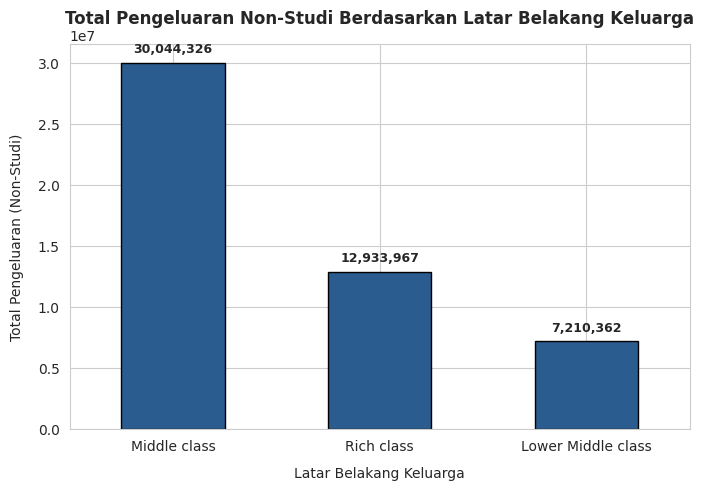

In [19]:
# 1. Mengelompokkan data berdasarkan Latar Belakang Keluarga dan Total Pengeluaran
kategori = df.groupby('Family_background')['Cost_without_study'].sum()
kategori = kategori.sort_values(ascending=False)

sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(8, 5))

# 3. Membuat Bar Chart
bars = kategori.plot(kind='bar', ax=ax, color='#2b5c8f', edgecolor='black')

plt.title('Total Pengeluaran Non-Studi Berdasarkan Latar Belakang Keluarga', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Latar Belakang Keluarga', fontsize=10, labelpad=10)
plt.ylabel('Total Pengeluaran (Non-Studi)', fontsize=10, labelpad=10)
plt.xticks(rotation=0)  # Kemiringan teks sumbu X (0 derajat agar tegak lurus)

for p in bars.patches:
    height = p.get_height()
    ax.annotate(f'{height:,.0f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

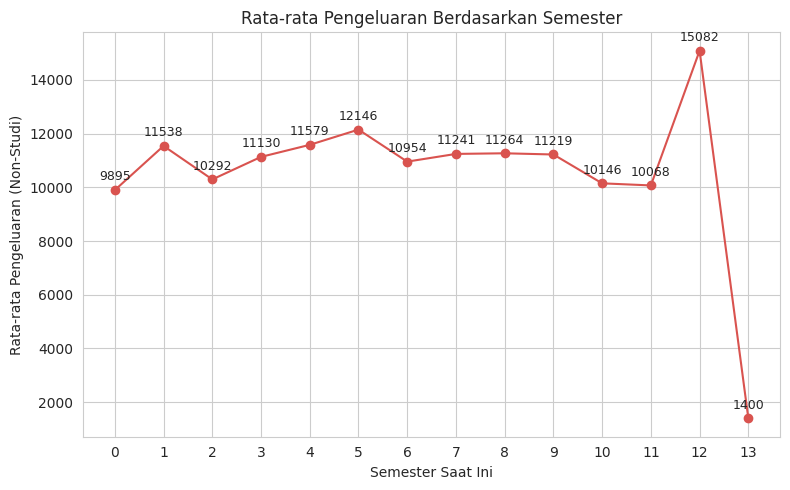

In [23]:

# 2. Buat Grafik
plt.figure(figsize=(8, 5))
plt.plot(tren.index, tren.values, marker='o', color='#d9534f')

# 3. Label Angka di Atas Titik (Format Bulat Sederhana)
for x, y in zip(tren.index, tren.values):
    plt.annotate(f'{int(y)}', (x, y), xytext=(0, 7),
                 textcoords='offset points', ha='center', fontsize=9)

plt.title('Rata-rata Pengeluaran Berdasarkan Semester')
plt.xlabel('Semester Saat Ini')
plt.ylabel('Rata-rata Pengeluaran (Non-Studi)')
plt.xticks(tren.index)
plt.tight_layout()
plt.show()

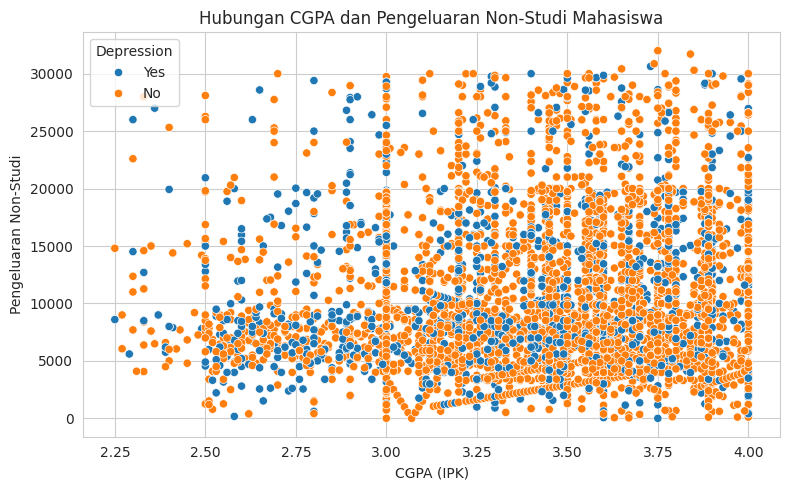

In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='CGPA', y='Cost_without_study', hue='Depression')
plt.title('Hubungan CGPA dan Pengeluaran Non-Studi Mahasiswa')
plt.xlabel('CGPA (IPK)')
plt.ylabel('Pengeluaran Non-Studi')
plt.tight_layout()
plt.show()

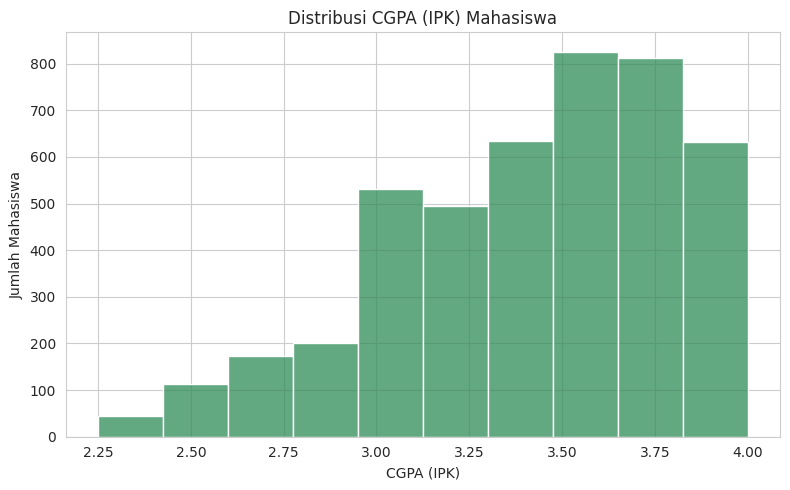

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='CGPA', bins=10, color='seagreen')

plt.title('Distribusi CGPA (IPK) Mahasiswa')
plt.xlabel('CGPA (IPK)')
plt.ylabel('Jumlah Mahasiswa')
plt.tight_layout()
plt.show()

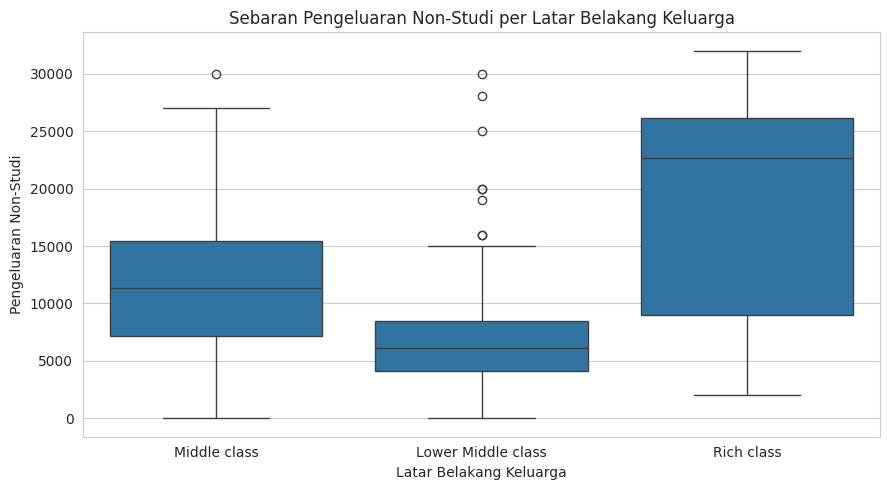

In [26]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Family_background', y='Cost_without_study')

plt.title('Sebaran Pengeluaran Non-Studi per Latar Belakang Keluarga')
plt.xlabel('Latar Belakang Keluarga')
plt.ylabel('Pengeluaran Non-Studi')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# 1. Menghitung Kuartil & IQR
Q1 = df['Cost_without_study'].quantile(0.25)
Q3 = df['Cost_without_study'].quantile(0.75)
IQR = Q3 - Q1

# 2. Menentukan Batas Bawah dan Batas Atas Outlier
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# 3. Menyaring Data Outlier
outlier = df[
    (df['Cost_without_study'] < batas_bawah) |
    (df['Cost_without_study'] > batas_atas)
]

# 4. Menampilkan Hasil Cetak
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Jumlah outlier:", len(outlier))

# 5. Menampilkan Contoh Data Outlier (Menggunakan kolom yang ada)
print("\nBeberapa contoh data outlier:")
print(outlier[['Age', 'Family_background', 'Living_style', 'Cost_without_study']].head())

Q1: 6100.0
Q3: 15439.0
IQR: 9339.0
Batas bawah: -7908.5
Batas atas: 29447.5
Jumlah outlier: 36

Beberapa contoh data outlier:
      Age Family_background Living_style  Cost_without_study
381    21        Rich class       Family               29747
520    21        Rich class     Bachelor               29796
574    21        Rich class     Bachelor               29769
619    24        Rich class     Bachelor               29553
1003   20        Rich class     Bachelor               29628


/tmp/ipykernel_4156/774110365.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kat.index, y=kat.values, ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_4156/774110365.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Living_style', y='Cost_without_study', ax=axes[1, 1], palette='Set2')


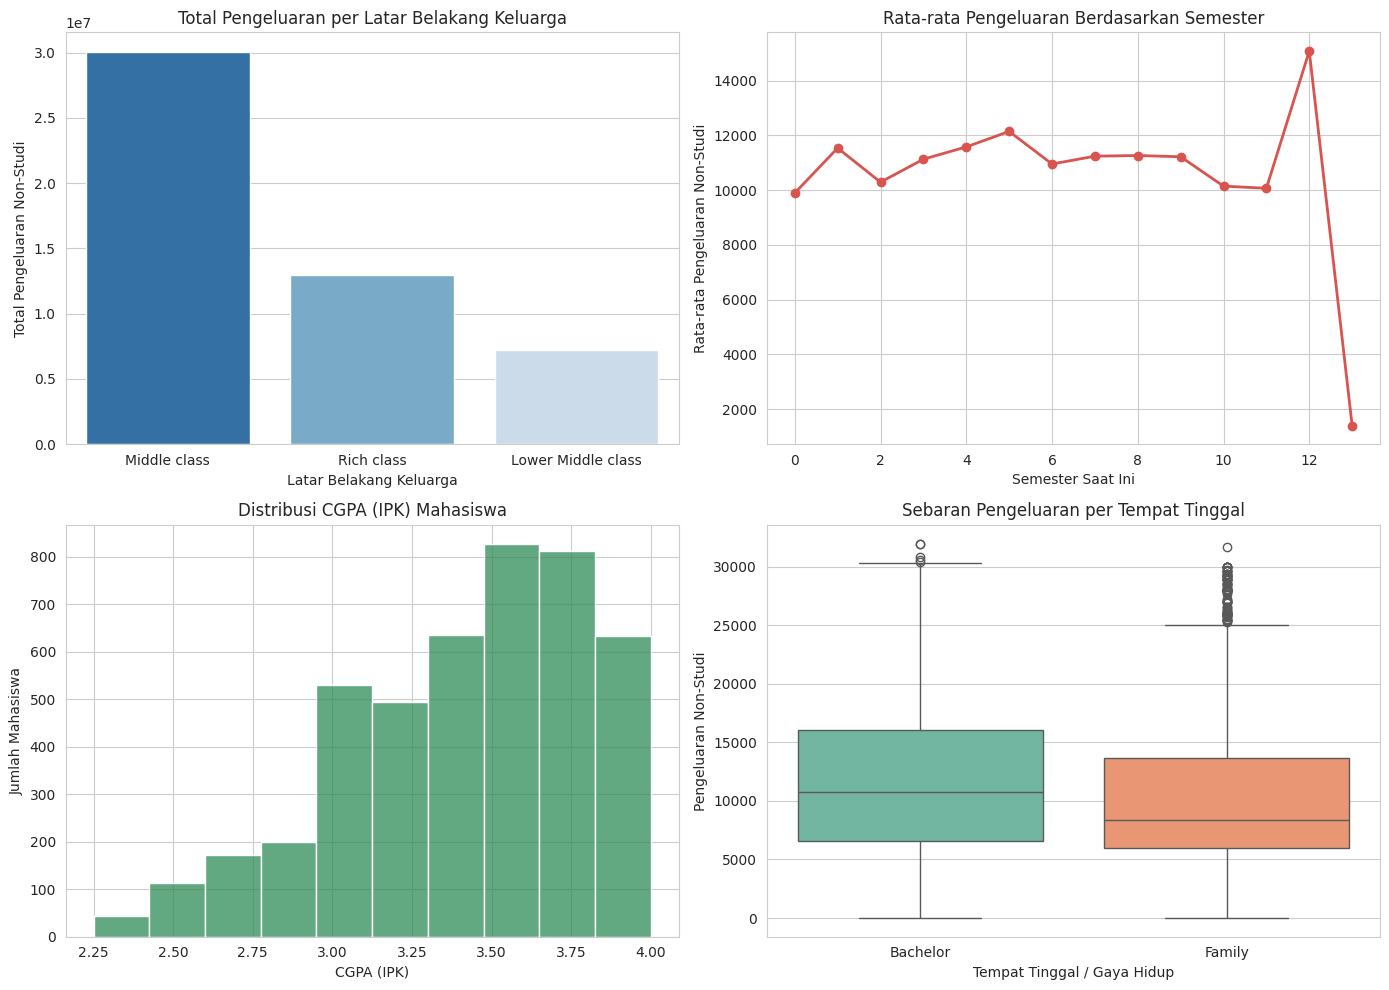

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Grafik 1 (axes[0, 0]): Total Pengeluaran Berdasarkan Latar Belakang Keluarga
kat = df.groupby('Family_background')['Cost_without_study'].sum().sort_values(ascending=False)
sns.barplot(x=kat.index, y=kat.values, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Total Pengeluaran per Latar Belakang Keluarga')
axes[0, 0].set_xlabel('Latar Belakang Keluarga')
axes[0, 0].set_ylabel('Total Pengeluaran Non-Studi')

# Grafik 2 (axes[0, 1]): Rata-rata Pengeluaran Berdasarkan Semester Saat Ini
tren = df.groupby('Current_semester')['Cost_without_study'].mean()
axes[0, 1].plot(tren.index, tren.values, marker='o', color='#d9534f', linewidth=2)
axes[0, 1].set_title('Rata-rata Pengeluaran Berdasarkan Semester')
axes[0, 1].set_xlabel('Semester Saat Ini')
axes[0, 1].set_ylabel('Rata-rata Pengeluaran Non-Studi')

# Grafik 3 (axes[1, 0]): Distribusi CGPA (IPK) Mahasiswa
sns.histplot(df['CGPA'], bins=10, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Distribusi CGPA (IPK) Mahasiswa')
axes[1, 0].set_xlabel('CGPA (IPK)')
axes[1, 0].set_ylabel('Jumlah Mahasiswa')

# Grafik 4 (axes[1, 1]): Sebaran Pengeluaran per Tempat Tinggal (Deteksi Outlier)
sns.boxplot(data=df, x='Living_style', y='Cost_without_study', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Sebaran Pengeluaran per Tempat Tinggal')
axes[1, 1].set_xlabel('Tempat Tinggal / Gaya Hidup')
axes[1, 1].set_ylabel('Pengeluaran Non-Studi')

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd

# 1. Load Data
df = pd.read_csv('Student_Depression_Dataset.csv')

# 2. Hitung Statistik Deskriptif (Mendefinisikan Variabel Kunci Dataset Student Depression)
total_pengeluaran = df['Cost_without_study'].sum()
rata_rata_pengeluaran = df['Cost_without_study'].mean()
keluarga_teratas = df.groupby('Family_background')['Cost_without_study'].sum().idxmax()
total_keluarga_teratas = df.groupby('Family_background')['Cost_without_study'].sum().max()
wilayah_teratas = df.groupby('Home_division')['Cost_without_study'].sum().idxmax()
total_wilayah_teratas = df.groupby('Home_division')['Cost_without_study'].sum().max()
cgpa_rata_rata = df['CGPA'].mean()

# Perhitungan Tambahan untuk Deteksi Outlier (Metode IQR)
Q1 = df['Cost_without_study'].quantile(0.25)
Q3 = df['Cost_without_study'].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
jumlah_outlier = len(df[df['Cost_without_study'] > batas_atas])

# 3. Cetak Laporan Output
print("\n" + "="*60)
print("=== LAPORAN ANALISIS DATA DEPRESI DAN PENGELUARAN MAHASISWA ===")
print("="*60)
print(f"""
1. Ringkasan Statistik Utama
   Total Pengeluaran Non-Studi : Rp {total_pengeluaran:,.0f}
   Rata-rata Pengeluaran        : Rp {rata_rata_pengeluaran:,.0f}
   Kategori Latar Belakang      : {keluarga_teratas} (Rp {total_keluarga_teratas:,.0f})
   Wilayah Asal Teratas         : {wilayah_teratas} (Rp {total_wilayah_teratas:,.0f})
   CGPA Rata-rata Mahasiswa     : {cgpa_rata_rata:.2f} / 4.00

2. Temuan Utama (Insight)
   - Kelompok mahasiswa dari latar belakang 'Middle class' menyumbang proporsi total pengeluaran non-studi terbesar secara signifikan dibandingkan kelompok lainnya.
   - Wilayah asal 'Dhaka' mencatatkan akumulasi pengeluaran biaya hidup non-studi tertinggi di antara seluruh divisi wilayah tempat tinggal mahasiswa.
   - Rata-rata capaian akademik mahasiswa (CGPA) tergolong sangat baik (3.41), namun terdapat variasi pengeluaran bulanan yang cukup tinggi antar-semester.

3. Potensi Outlier
   - Terdeteksi {jumlah_outlier} data outlier pada variabel pengeluaran non-studi (nilai pengeluaran di atas Rp {batas_atas:,.0f}).
   - Penjelasan Penyebab: Mayoritas data pencilan ini berasal dari kelompok mahasiswa kategori 'Rich class' yang tinggal secara mandiri (bachelor/kos). Hal ini wajar mengingat gaya hidup dan daya beli kelompok tersebut jauh di atas rata-rata populasi mahasiswa umum.

4. Rekomendasi Bisnis & Kelembagaan
   Berdasarkan hasil analisis data mahasiswa, strategi intervensi dan pengelolaan kesejahteraan disarankan berfokus pada tiga pilar utama. Pertama, pihak pengelola kampus dan penyedia layanan mahasiswa di wilayah Dhaka perlu menyediakan program pendampingan finansial serta edukasi penganggaran bulanan, mengingat pengeluaran mahasiswa di wilayah ini merupakan yang tertinggi. Kedua, kelompok mahasiswa dari latar belakang 'Middle class' dan mahasiswa berstatus tinggal mandiri (bachelor) perlu mendapatkan prioritas dalam akses program dukungan kesejahteraan mental maupun alokasi beasiswa biaya hidup. Ketiga, perlu adanya pemantauan berkala terhadap mahasiswa semester menengah hingga akhir yang memiliki indikasi pencilan pengeluaran tinggi agar beban finansial di luar perkuliahan tidak berdampak negatif terhadap konsistensi capaian akademik (CGPA) mereka.
""")


=== LAPORAN ANALISIS DATA DEPRESI DAN PENGELUARAN MAHASISWA ===

1. Ringkasan Statistik Utama
   Total Pengeluaran Non-Studi : Rp 50,188,655
   Rata-rata Pengeluaran        : Rp 11,243
   Kategori Latar Belakang      : Middle class (Rp 30,044,326)
   Wilayah Asal Teratas         : Dhaka (Rp 15,484,022)
   CGPA Rata-rata Mahasiswa     : 3.41 / 4.00

2. Temuan Utama (Insight)
   - Kelompok mahasiswa dari latar belakang 'Middle class' menyumbang proporsi total pengeluaran non-studi terbesar secara signifikan dibandingkan kelompok lainnya.
   - Wilayah asal 'Dhaka' mencatatkan akumulasi pengeluaran biaya hidup non-studi tertinggi di antara seluruh divisi wilayah tempat tinggal mahasiswa.
   - Rata-rata capaian akademik mahasiswa (CGPA) tergolong sangat baik (3.41), namun terdapat variasi pengeluaran bulanan yang cukup tinggi antar-semester.

3. Potensi Outlier
   - Terdeteksi 36 data outlier pada variabel pengeluaran non-studi (nilai pengeluaran di atas Rp 29,448).
   - Penjelasan Penyeba

**Laporan Rekomendasi**

